# Assignment 3 · Part 2a — Transfer learning and fine-tuning on lot names
## Predicting failed public-procurement contracts in Kazakhstan

**Author:** Aziz Abdulin · **Project:** Tender Risk ML · **Repository:** https://github.com/awzwz/tender-risk-ml

Notebook 04 showed that tuning a model on the 20 midterm features has reached a plateau. The largest piece of
information the table does not contain is **what is being bought**: "office paper A4" and "capital repair of a school
roof" can have the same value and method but fail at very different rates. Every procurement has the Russian names of
its lots (`lot_names`, filled for 100 % of procurements, median 5 words). This notebook asks two questions:

| § | Question | A3 criterion |
|---|---|---|
| 1 | Setup, the text and how it is split | — |
| 2 | **Transfer learning**: does a language model pretrained on general Russian text produce useful features for our task without any training on it? Three encoders are compared. | 4 · Transfer learning |
| 3 | **Fine-tuning**: does adapting all weights of a small Russian encoder to failed contracts extract more than the frozen features? | 3 · Fine-tuning |
| 4 | Scores saved for the comparison with TF-IDF and the tabular model (05b) and for stacking | — |

**How to run:** `Kernel → Restart & Run All` on a machine with a GPU (Apple MPS or CUDA; CPU works but is slow).
The first run computes embeddings and fine-tunes (≈ 1 hour on an Apple M-series laptop); results are cached in
`data/processed/` and `data/predictions/`, so a re-run reuses them and finishes in a few minutes. To recompute
everything set `RECOMPUTE = True`.

## 1. Setup and the text

In [1]:
# Google Colab only: uncomment and run this cell first.
# !git clone -q https://github.com/awzwz/tender-risk-ml
# import os; os.chdir("tender-risk-ml/notebooks")

In [2]:
import json, math, os, sys, time, warnings
from pathlib import Path

os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"           # keep download / loading bars out of the notebook

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import transformers
from transformers import AutoModel, AutoModelForSequenceClassification, AutoTokenizer, get_linear_schedule_with_warmup
transformers.logging.set_verbosity_error(); transformers.logging.disable_progress_bar()

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160); pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
SEED = 42
RECOMPUTE = False

ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src import prepare as P
from src.metrics import average_precision, roc_auc, top_k

DEV = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
PROC = ROOT / "data" / "processed"; PRED = ROOT / "data" / "predictions"; PRED.mkdir(parents=True, exist_ok=True)
FIG = ROOT / "figures"; FIG.mkdir(exist_ok=True)
RES = ROOT / "results" / "a3_05"; RES.mkdir(parents=True, exist_ok=True)
print("device:", DEV, "| torch", torch.__version__)

W1028 00:56:23.195000 86340 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


device: mps | torch 2.14.1


In [3]:
df = P.load_model_table(ROOT)
df["text"] = df[P.TEXT_FEATURE].fillna("").str.lower().str.strip()
y = P.TARGET
train, val, test = (df[df.split == s].reset_index(drop=True) for s in ("train", "val", "test"))
seen = set(train.text)
words = df.text.str.split().str.len()
pd.Series({
    "procurements": len(df), "unique texts": df.text.nunique(),
    "words per text, median": words.median(), "words per text, 90th percentile": words.quantile(0.9),
    "test texts never seen in train, share of test rows": (~test.text.isin(seen)).mean(),
    "failure rate, test rows with unseen text": test.loc[~test.text.isin(seen), y].mean(),
    "failure rate, test rows with seen text": test.loc[test.text.isin(seen), y].mean(),
}).to_frame("value")

,value
procurements,"358,789.000"
unique texts,"60,895.000"
"words per text, median",5.000
"words per text, 90th percentile",13.000
"test texts never seen in train, share of test rows",0.223
"failure rate, test rows with unseen text",0.097
"failure rate, test rows with seen text",0.057


Two properties of this text drive every design choice below:

* **It is short and repetitive** — catalogue names, not prose. A few hundred templates ("услуги связи", "бумага для
  офисной техники") cover most procurements. A model can score well simply by memorising the failure rate of
  frequent templates, so every result is also reported separately for **test procurements whose text never appears
  in train**: only there does the model have to *understand* the text.
* **It is in Russian with Kazakh-specific vocabulary** (place names, state bodies), so the encoders must have a
  Russian vocabulary.

In [4]:
def report(name, p_val, p_test):
    # PR-AUC / ROC-AUC on validation and test, and on test split into seen / unseen texts
    unseen = ~test.text.isin(seen).to_numpy(); yt = test[y].to_numpy()
    return {"model": name, "val PR-AUC": average_precision(val[y], p_val), "test PR-AUC": average_precision(yt, p_test),
            "test ROC-AUC": roc_auc(yt, p_test), "test P@1%": top_k(yt, p_test, 0.01)[0],
            "test PR-AUC, seen texts": average_precision(yt[~unseen], p_test[~unseen]),
            "test PR-AUC, unseen texts": average_precision(yt[unseen], p_test[unseen]),
            "test ROC-AUC, unseen texts": roc_auc(yt[unseen], p_test[unseen])}

uniq = pd.Series(sorted(df.text.unique()))                  # every model works on unique texts, then maps back
pos = pd.Series(np.arange(len(uniq)), index=uniq.values)
row_idx = {s: pos[d.text].to_numpy() for s, d in (("train", train), ("val", val), ("test", test))}

## 2. Transfer learning: frozen encoders as feature extractors

**Idea.** A transformer pretrained on large Russian corpora already maps similar phrases ("ремонт кровли",
"капитальный ремонт крыши") to nearby vectors. If that knowledge transfers, a *linear* classifier on the frozen
vectors — no update of the encoder at all — should separate risky purchases, including names it has never seen.

**Encoders compared** (all public on Hugging Face, all with a Russian vocabulary):

| Encoder | Parameters | Pretraining | Pooling | Why in the comparison |
|---|---|---|---|---|
| `cointegrated/rubert-tiny2` | 29 M | Russian sentence embeddings (distilled from larger models) | [CLS], as recommended by the author | small and fast — the candidate for fine-tuning |
| `intfloat/multilingual-e5-small` | 118 M | contrastive training on ~1 billion text pairs, 100 languages | mean over tokens, prefix `query: ` | strong general-purpose embeddings; tests whether a multilingual model loses anything on Russian |
| `DeepPavlov/rubert-base-cased` | 178 M | masked-language model on Russian Wikipedia and news | mean over tokens | a large Russian model; tests whether capacity matters for 5-word texts |

**Classifier on top (the "probe").** Logistic regression trained in PyTorch on the frozen vectors of train
procurements (class-weighted binary cross-entropy, AdamW, early stopping on validation PR-AUC). Using the same simple
probe for every encoder makes the comparison about the *representations*, not about the classifier.

In [5]:
ENCODERS = {
    "rubert-tiny2": ("cointegrated/rubert-tiny2", "cls", ""),
    "multilingual-e5-small": ("intfloat/multilingual-e5-small", "mean", "query: "),
    "rubert-base-cased": ("DeepPavlov/rubert-base-cased", "mean", ""),
}

@torch.no_grad()
def embed(hf_name, pooling, prefix, texts, batch=256, max_len=64):
    tok = AutoTokenizer.from_pretrained(hf_name); enc = AutoModel.from_pretrained(hf_name).to(DEV).eval()
    out = []
    for i in range(0, len(texts), batch):
        b = tok([prefix + t for t in texts[i:i + batch]], padding=True, truncation=True, max_length=max_len,
                return_tensors="pt").to(DEV)
        h = enc(**b).last_hidden_state
        if pooling == "cls":
            e = h[:, 0]
        else:
            m = b["attention_mask"].unsqueeze(-1).float(); e = (h * m).sum(1) / m.sum(1)
        out.append(torch.nn.functional.normalize(e, dim=-1).float().cpu())
    n_params = sum(p.numel() for p in enc.parameters())
    del enc
    if DEV == "mps": torch.mps.empty_cache()
    return torch.cat(out).numpy(), n_params

emb, enc_info = {}, {}
for key, (hf, pooling, prefix) in ENCODERS.items():
    f = PROC / f"emb_{key}.npy"
    if f.exists() and not RECOMPUTE:
        emb[key] = np.load(f); enc_info[key] = json.loads((RES / f"emb_{key}.json").read_text())
    else:
        t = time.time(); E, n_params = embed(hf, pooling, prefix, list(uniq))
        np.save(f, E); emb[key] = E
        enc_info[key] = {"parameters": n_params, "dim": E.shape[1], "seconds": round(time.time() - t, 1)}
        (RES / f"emb_{key}.json").write_text(json.dumps(enc_info[key]))
uniq.to_frame("text").to_parquet(PROC / "emb_texts.parquet", index=False)
pd.DataFrame(enc_info).T.rename(columns={"seconds": f"seconds for {len(uniq):,} texts"})

,parameters,dim,"seconds for 60,895 texts"
rubert-tiny2,"29,193,768.000",312.000,49.600
multilingual-e5-small,"117,653,760.000",384.000,241.000
rubert-base-cased,"177,853,440.000",768.000,652.300


In [6]:
def linear_probe(E, epochs=60, lr=1e-2, wd=1e-4, patience=6):
    # logistic regression on frozen vectors, trained with PyTorch; best epoch chosen on validation PR-AUC
    torch.manual_seed(SEED)
    Xtr = torch.tensor(E[row_idx["train"]], device=DEV); ytr = torch.tensor(train[y].to_numpy(), dtype=torch.float32, device=DEV)
    Xva = torch.tensor(E[row_idx["val"]], device=DEV); Xte = torch.tensor(E[row_idx["test"]], device=DEV)
    lin = torch.nn.Linear(E.shape[1], 1).to(DEV)
    opt = torch.optim.AdamW(lin.parameters(), lr=lr, weight_decay=wd)
    loss_fn = torch.nn.BCEWithLogitsLoss(pos_weight=((1 - ytr.mean()) / ytr.mean()).detach())
    best, best_state, wait = -1, None, 0
    g = torch.Generator(device="cpu").manual_seed(SEED)
    for ep in range(epochs):
        for idx in torch.randperm(len(Xtr), generator=g).split(4096):
            idx = idx.to(DEV); opt.zero_grad(); loss_fn(lin(Xtr[idx]).squeeze(1), ytr[idx]).backward(); opt.step()
        with torch.no_grad():
            s = average_precision(val[y], torch.sigmoid(lin(Xva)).squeeze(1).cpu().numpy())
        if s > best:
            best, wait, best_state = s, 0, {k: v.clone() for k, v in lin.state_dict().items()}
        else:
            wait += 1
            if wait >= patience: break
    lin.load_state_dict(best_state)
    with torch.no_grad():
        return (torch.sigmoid(lin(Xva)).squeeze(1).cpu().numpy(), torch.sigmoid(lin(Xte)).squeeze(1).cpu().numpy())

probe_rows, probe_preds = [], {}
for key, E in emb.items():
    pv, pt = linear_probe(E)
    probe_preds[key] = (pv, pt)
    probe_rows.append(report(f"frozen {key} + linear probe", pv, pt))
probes = pd.DataFrame(probe_rows).set_index("model"); probes

,val PR-AUC,test PR-AUC,test ROC-AUC,test P@1%,"test PR-AUC, seen texts","test PR-AUC, unseen texts","test ROC-AUC, unseen texts"
model,,,,,,,
frozen rubert-tiny2 + linear probe,0.164,0.125,0.667,0.190,0.104,0.172,0.640
frozen multilingual-e5-small + linear probe,0.174,0.131,0.676,0.201,0.109,0.189,0.659
frozen rubert-base-cased + linear probe,0.172,0.133,0.681,0.206,0.110,0.187,0.655


**Reading the table.** The frozen encoders separate failures from non-failures far better than chance (6.6 %), so
general Russian knowledge *does* transfer: the vectors encode which kind of purchase this is. The column that
matters is **unseen texts** — names the probe has never seen during training. In the pilot study the frozen
rubert-tiny2 probe was weaker there than a TF-IDF model (0.172 vs 0.200); notebook 05b repeats that comparison and
also tests the vectors *inside* the tabular model, where the pilot found them useful (+0.036 PR-AUC).

## 3. Fine-tuning rubert-tiny2

**Why this model.** With 29 M parameters it fine-tunes fully on a laptop GPU (measured: 1.8 minutes per epoch), so
the hyper-parameters below can actually be compared instead of guessed. Parameter-efficient methods (LoRA) are not
needed at this size; they are used for the 1.5 B-parameter LLM in notebook 06.

**Training data.** Train procurements, but **at most 20 rows per unique text**: 951 frequent templates make up 78 %
of the training rows, and without the cap the model would mostly learn the failure rate of "communication services"
instead of language. The cap keeps every distinct text and its label mix while removing the repetition.

| Hyper-parameter | Value | Why |
|---|---|---|
| Model | `rubert-tiny2` + new linear head with 2 outputs | §2; the head is the only randomly initialised part |
| Trainable parameters | all ≈ 29.2 M | the model is small, full fine-tuning is affordable |
| Max length | 64 tokens | 90 % of texts have ≤ 13 words |
| Learning rate | **searched**: 2e-5, 5e-5, 1e-4 | the most influential setting for fine-tuning; three values span the usual range |
| Schedule | linear warm-up over 6 % of steps, then linear decay to 0 | warm-up protects pretrained weights from large gradients of the random head |
| Batch size | 64 | fits easily in memory; 0.086 s per step measured |
| Epochs | 3, the best epoch by validation PR-AUC is kept | small models start memorising repeated texts after 2–3 epochs |
| Optimiser | AdamW, weight decay 0.01 | standard for transformers |
| Loss | cross-entropy with the failure class weighted by the negative/positive ratio of the capped train set | the class imbalance changes after capping, the weight follows the actual data |
| Seeds | the best learning rate is re-run with seeds 42, 43, 44 | shows how much of a difference is noise |

In [7]:
CAP, MAX_LEN, BATCH, EPOCHS, WARMUP = 20, 64, 64, 3, 0.06
NAME = ENCODERS["rubert-tiny2"][0]
tok = AutoTokenizer.from_pretrained(NAME)

shuffled = train.sample(frac=1, random_state=SEED)
capped = shuffled[shuffled.groupby("text").cumcount() < CAP].reset_index(drop=True)   # ≤ 20 random rows per text
print(f"train rows {len(train):,} -> capped {len(capped):,}; unique texts {capped.text.nunique():,}; "
      f"failure rate {capped[y].mean():.3f} (full train {train[y].mean():.3f})")

def encode(texts):
    return tok(list(texts), padding="max_length", truncation=True, max_length=MAX_LEN, return_tensors="pt")

ENC_ALL = encode(uniq)                                    # tokenised once: every prediction is per unique text

@torch.no_grad()
def predict_texts(model, batch=1024):
    model.eval(); out = []
    for i in range(0, len(uniq), batch):
        b = {k: v[i:i + batch].to(DEV) for k, v in ENC_ALL.items()}
        out.append(torch.softmax(model(**b).logits.float(), -1)[:, 1].cpu())
    return torch.cat(out).numpy()                          # score for every unique text

def fine_tune(rows, lr, seed, epochs=EPOCHS, stop_after=None, eval_rows=None, log=None):
    # trains on `rows` (a DataFrame with text + label); returns per-epoch text scores and the model.
    # The learning-rate schedule always spans `epochs`; `stop_after` ends training early at the chosen epoch, so
    # every run follows exactly the schedule of the run in which that epoch was selected.
    torch.manual_seed(seed); np.random.seed(seed)
    model = AutoModelForSequenceClassification.from_pretrained(NAME, num_labels=2).to(DEV)
    enc = encode(rows.text); lab = torch.tensor(rows[y].to_numpy(), dtype=torch.long)
    w = (lab == 0).sum().item() / max((lab == 1).sum().item(), 1)
    loss_fn = torch.nn.CrossEntropyLoss(weight=torch.tensor([1.0, w], device=DEV))
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    steps = epochs * math.ceil(len(rows) / BATCH)
    sched = get_linear_schedule_with_warmup(opt, int(WARMUP * steps), steps)
    g = torch.Generator().manual_seed(seed); per_epoch = []
    for ep in range(stop_after or epochs):
        model.train(); t = time.time(); losses = []
        for idx in torch.randperm(len(rows), generator=g).split(BATCH):
            b = {k: v[idx].to(DEV) for k, v in enc.items()}
            loss = loss_fn(model(**b).logits, lab[idx].to(DEV))
            opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); sched.step()
            losses.append(loss.item())
        scores = predict_texts(model)
        rec = {"lr": lr, "seed": seed, "epoch": ep + 1, "train loss": float(np.mean(losses)), "minutes": (time.time() - t) / 60}
        if eval_rows is not None:
            rec["val PR-AUC"] = average_precision(eval_rows[y], scores[pos[eval_rows.text].to_numpy()])
        per_epoch.append((rec, scores))
        if log is not None: log.append(rec)
    return per_epoch, model

train rows 266,294 -> capped 78,584; unique texts 41,737; failure rate 0.095 (full train 0.066)


In [8]:
grid_file = RES / "finetune_grid.json"
if grid_file.exists() and not RECOMPUTE:
    grid_log = json.loads(grid_file.read_text()); text_scores = {k: np.load(PROC / f"ft_scores_{k}.npy") for k in json.loads((RES / "ft_runs.json").read_text())}
else:
    grid_log, text_scores = [], {}
    for lr in (2e-5, 5e-5, 1e-4):
        per_epoch, _ = fine_tune(capped, lr, SEED, eval_rows=val, log=grid_log)
        best_rec, best_scores = max(per_epoch, key=lambda r: r[0]["val PR-AUC"])
        key = f"lr{lr:g}_seed{SEED}"; text_scores[key] = best_scores; np.save(PROC / f"ft_scores_{key}.npy", best_scores)
    grid_file.write_text(json.dumps(grid_log)); (RES / "ft_runs.json").write_text(json.dumps(list(text_scores)))
grid = pd.DataFrame(grid_log)
grid.assign(lr=grid.lr.map(lambda v: f"{v:g}")).query("seed == 42")

,lr,seed,epoch,train loss,minutes,val PR-AUC
0,2e-05,42,1,0.657,4.175,0.176
1,2e-05,42,2,0.627,4.153,0.188
2,2e-05,42,3,0.612,4.529,0.193
3,5e-05,42,1,0.651,4.314,0.191
4,5e-05,42,2,0.608,4.538,0.196
5,5e-05,42,3,0.581,4.495,0.199
6,0.0001,42,1,0.651,4.317,0.193
7,0.0001,42,2,0.599,70.040,0.196
8,0.0001,42,3,0.563,3.474,0.197


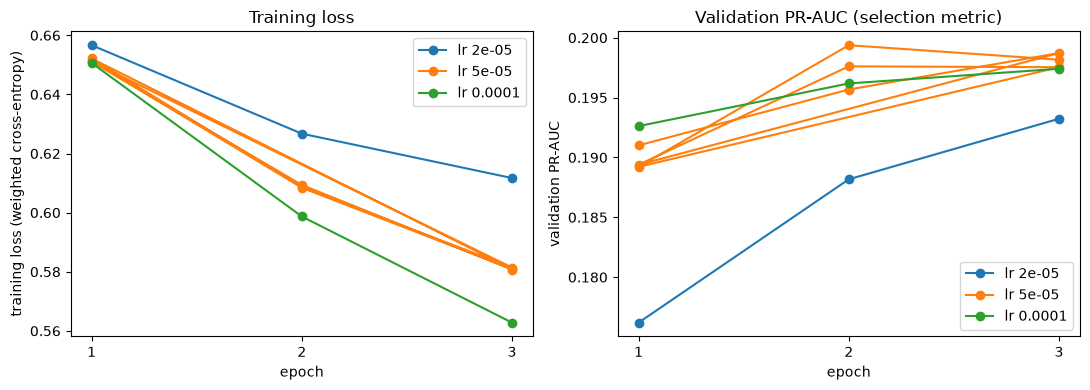

chosen: learning rate 5e-05, epoch 2


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for lr, g in grid.groupby("lr"):
    ax[0].plot(g.epoch, g["train loss"], "o-", label=f"lr {lr:g}")
    ax[1].plot(g.epoch, g["val PR-AUC"], "o-", label=f"lr {lr:g}")
ax[0].set(xlabel="epoch", ylabel="training loss (weighted cross-entropy)", title="Training loss", xticks=[1, 2, 3])
ax[1].set(xlabel="epoch", ylabel="validation PR-AUC", title="Validation PR-AUC (selection metric)", xticks=[1, 2, 3])
for a in ax: a.legend()
plt.tight_layout(); plt.savefig(FIG / "a3_05_finetune_curves.png", dpi=150, bbox_inches="tight"); plt.show()
best_lr = float(grid.loc[grid["val PR-AUC"].idxmax(), "lr"]); best_epoch = int(grid.loc[grid["val PR-AUC"].idxmax(), "epoch"])
print(f"chosen: learning rate {best_lr:g}, epoch {best_epoch}")

*The 70-minute epoch in the table is the laptop sleeping during the run, not training time; a normal epoch takes
3.5–4.5 minutes here (1.8 minutes without other jobs running).*

**Seed stability.** The chosen learning rate is trained again with two more seeds; the spread between seeds is the
noise level against which every difference in this part has to be judged.

In [10]:
for seed in (43, 44):
    key = f"lr{best_lr:g}_seed{seed}"
    if key in text_scores: continue
    per_epoch, _ = fine_tune(capped, best_lr, seed, stop_after=best_epoch, eval_rows=val, log=grid_log)
    text_scores[key] = per_epoch[-1][1]; np.save(PROC / f"ft_scores_{key}.npy", text_scores[key])
grid_file.write_text(json.dumps(grid_log)); (RES / "ft_runs.json").write_text(json.dumps(list(text_scores)))

seed_rows = [report(f"fine-tuned, seed {k.split('seed')[1]}", s[row_idx["val"]], s[row_idx["test"]])
             for k, s in text_scores.items() if k.startswith(f"lr{best_lr:g}_")]
seeds = pd.DataFrame(seed_rows).set_index("model")
seeds.loc["mean ± std"] = [f"{seeds[c].mean():.3f} ± {seeds[c].std():.3f}" for c in seeds.columns]
seeds

,val PR-AUC,test PR-AUC,test ROC-AUC,test P@1%,"test PR-AUC, seen texts","test PR-AUC, unseen texts","test ROC-AUC, unseen texts"
model,,,,,,,
"fine-tuned, seed 42",0.199,0.156,0.697,0.242,0.124,0.228,0.706
"fine-tuned, seed 43",0.198,0.152,0.699,0.242,0.124,0.231,0.706
"fine-tuned, seed 44",0.198,0.155,0.699,0.237,0.123,0.237,0.713
mean ± std,0.198 ± 0.001,0.154 ± 0.002,0.698 ± 0.001,0.240 ± 0.003,0.123 ± 0.001,0.232 ± 0.005,0.709 ± 0.004


In [11]:
# fine-tuned model of record: seed 42 at the chosen learning rate; compared with the frozen probes
ft_key = f"lr{best_lr:g}_seed{SEED}"
s = text_scores[ft_key]
comparison = pd.concat([probes, pd.DataFrame([report("fine-tuned rubert-tiny2", s[row_idx["val"]], s[row_idx["test"]])]).set_index("model")])
comparison

,val PR-AUC,test PR-AUC,test ROC-AUC,test P@1%,"test PR-AUC, seen texts","test PR-AUC, unseen texts","test ROC-AUC, unseen texts"
model,,,,,,,
frozen rubert-tiny2 + linear probe,0.164,0.125,0.667,0.190,0.104,0.172,0.640
frozen multilingual-e5-small + linear probe,0.174,0.131,0.676,0.201,0.109,0.189,0.659
frozen rubert-base-cased + linear probe,0.172,0.133,0.681,0.206,0.110,0.187,0.655
fine-tuned rubert-tiny2,0.199,0.156,0.697,0.242,0.124,0.228,0.706


### 3.1 Out-of-fold scores for stacking

To use the fine-tuned score as a *feature* of the tabular model (05b, 07), the score of every train procurement must
come from a model that **did not see that procurement** — otherwise the score on train is far better than on new
data and the tabular model learns to trust it too much. Train texts are split into 5 groups (a text never appears in
two groups); for each group a model is fine-tuned on the other four with the chosen learning rate and number of
epochs and scores the held-out group.

In [12]:
oof_file = PRED / "05_rubert_oof_train.parquet"
if oof_file.exists() and not RECOMPUTE:
    oof = pd.read_parquet(oof_file)
else:
    rng = np.random.default_rng(SEED)
    texts = capped.text.unique(); fold_of = pd.Series(rng.integers(0, 5, len(texts)), index=texts)
    oof_text = pd.Series(np.nan, index=uniq.values)
    for k in range(5):
        t = time.time()
        held = fold_of[fold_of == k].index
        per_epoch, _ = fine_tune(capped[~capped.text.isin(held)], best_lr, SEED, stop_after=best_epoch)
        scores = per_epoch[-1][1]
        oof_text.loc[held] = scores[pos[held].to_numpy()]
        print(f"fold {k + 1}/5: {len(held):,} held-out texts, {(time.time() - t) / 60:.1f} min", flush=True)
    oof = pd.DataFrame({"id": train.id, "score": oof_text.loc[train.text].to_numpy()})
    oof.to_parquet(oof_file, index=False)
print(f"out-of-fold train PR-AUC {average_precision(train[y], oof.score.to_numpy()):.3f} "
      f"(validation PR-AUC of the full model {comparison.loc['fine-tuned rubert-tiny2', 'val PR-AUC']:.3f})")

out-of-fold train PR-AUC 0.236 (validation PR-AUC of the full model 0.199)


## 4. Saved scores

| File | Content | Used in |
|---|---|---|
| `data/processed/emb_<encoder>.npy` + `emb_texts.parquet` | frozen vectors of every unique text, three encoders | 05b (encoders inside LightGBM) |
| `data/predictions/05_probe_<encoder>.parquet` | linear-probe scores, validation and test | 05b, 07 |
| `data/predictions/05_rubert_finetuned.parquet` | fine-tuned scores, validation and test | 05b, 07 |
| `data/predictions/05_rubert_oof_train.parquet` | out-of-fold fine-tuned scores for train | 05b, 07 (stacking) |

In [13]:
def save(name, p_val, p_test):
    pd.DataFrame({"id": np.r_[val.id, test.id], "split": ["val"] * len(val) + ["test"] * len(test),
                  "score": np.r_[p_val, p_test]}).to_parquet(PRED / f"{name}.parquet", index=False)

for key, (pv, pt) in probe_preds.items():
    save(f"05_probe_{key}", pv, pt)
save("05_rubert_finetuned", s[row_idx["val"]], s[row_idx["test"]])
comparison.to_csv(RES / "text_models.csv")
(RES / "finetune_choice.json").write_text(json.dumps({"learning_rate": best_lr, "epochs": best_epoch, "cap_per_text": CAP,
                                                     "max_len": MAX_LEN, "batch": BATCH, "warmup": WARMUP}, indent=2))
print(sorted(f.name for f in PRED.glob("05_*.parquet")))

['05_probe_multilingual-e5-small.parquet', '05_probe_rubert-base-cased.parquet', '05_probe_rubert-tiny2.parquet', '05_rubert_finetuned.parquet', '05_rubert_oof_train.parquet']


**Summary of this notebook** (the comparison with TF-IDF and with the tabular model is in 05b):

* *Transfer learning (criterion 4).* Frozen Russian encoders rank failures well above chance from the lot names
  alone (test PR-AUC 0.125–0.133 against 0.066 without a model; 0.17–0.19 on texts never seen in training), so
  knowledge from general text does transfer. Size and multilingual training matter little: the 118 M-parameter e5
  and the 178 M-parameter rubert-base beat the 29 M rubert-tiny2 by only 0.006–0.008, at 5–13 times the
  computation. For 5-word catalogue names a small model is enough.
* *Fine-tuning (criterion 3).* Adapting all 29 M weights of rubert-tiny2 (learning rate 5e-5 chosen from three, 3
  epochs, warm-up, weighted loss) raises test PR-AUC to **0.154 ± 0.002** over three seeds and, more importantly,
  to **0.232 ± 0.005 on unseen texts** (frozen probe: 0.172; ROC-AUC 0.709 vs 0.640). The seed spread is a tenth of
  the gain, so fine-tuning genuinely extracts more from the text than frozen features — it learns which words
  signal risk in procurement, not just which phrases are similar in general Russian.
* *Text alone is weak.* Even the fine-tuned model is far below the tabular models (0.31 on the 20 features): the name
  of what is bought is a useful complement, not a substitute for the value, method and competition of the
  procurement. Whether the complement adds to the tabular model is measured in 05b.